# code_203 · A local attribution depends on the reference game

**Book:** section 38.3. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_38_GUIDE.md), [execution evidence](../CHAPTER_38_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_203).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Explanation contracts identify the fitted function, target output, reference population, permitted perturbations and action limits. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8003;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8003


<a id="define-the-coalition-game"></a>
 ## Enumerate a declared game instead of treating attribution as a unique property
 Fit a fixed source histogram classifier to 1,000 generated structures. Load and strain proxy are strongly correlated; an independent sensor also predicts a noisy actionable finding. Explain the fixed query [1.4,1.4,0.4] in probability units. One background contains120 random source records; another contains the first120 source records with load above0.75. Both are valid reference populations with different questions. For each of all eight feature coalitions, replace present features by query values and keep absent features jointly from a background row, then average model probabilities. This is an explicitly interventional empirical-background game: missing-feature rows retain their mutual dependence but can be incompatible with the fixed query features. It is not a conditional expectation under a fitted causal model.

 Compute exact Shapley values from the three-feature factorial formula. The baseline plus contributions must reconstruct this same model probability to rounding; enumerate all coalitions and verify the identity independently. No SHAP package or approximate TreeSHAP result is falsely claimed. The predictor and query stay fixed when the background changes.


,baseline,load,strain,sensor
Mixed source,0.316595,0.458357,-0.006906,0.034371
High-load source,0.742060,0.015851,-0.020920,0.065428


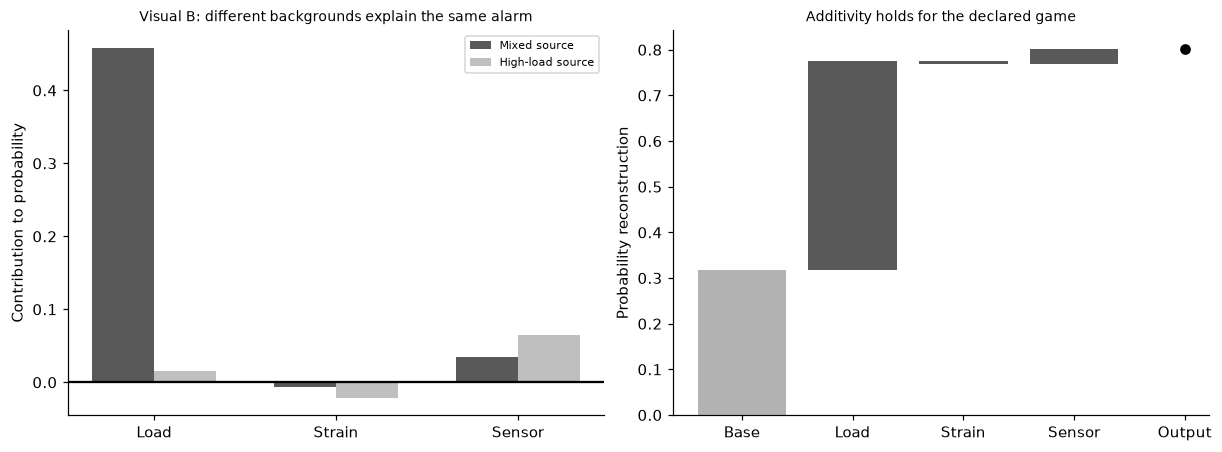

In [2]:
import math,itertools
from sklearn.ensemble import HistGradientBoostingClassifier
load=rng.normal(size=1000);strain=.97*load+np.sqrt(1-.97**2)*rng.normal(size=1000);sensor=rng.normal(size=1000);xs=np.c_[load,strain,sensor];ys=rng.binomial(1,expit(-.6+1.6*load+.6*sensor));model=HistGradientBoostingClassifier(max_iter=100,max_depth=3,early_stopping=False,random_state=SEED).fit(xs,ys);query=np.array([1.4,1.4,.4]);prediction=float(model.predict_proba(query[None])[:,1][0]);backgrounds={'Mixed source':xs[rng.choice(1000,120,replace=False)],'High-load source':xs[xs[:,0]>.75][:120]};assert all(len(b)==120 for b in backgrounds.values())
def shapley(background):
    values={}
    for mask in range(8):
        z=background.copy()
        for j in range(3):
            if mask&(1<<j):z[:,j]=query[j]
        values[mask]=float(model.predict_proba(z)[:,1].mean())
    phi=np.zeros(3)
    for j in range(3):
        for mask in range(8):
            if not mask&(1<<j):
                size=mask.bit_count();weight=math.factorial(size)*math.factorial(2-size)/math.factorial(3);phi[j]+=weight*(values[mask|(1<<j)]-values[mask])
    assert np.isclose(values[0]+phi.sum(),prediction,atol=1e-12);return phi,values
explanations={name:shapley(b) for name,b in backgrounds.items()};assert np.allclose([v[1][7] for v in explanations.values()],prediction);RESULTS.update(source_records=1000,query=query.tolist(),query_probability=prediction,attribution_output_scale='probability',coalition_game='interventional finite empirical background',background_sizes={k:len(v) for k,v in backgrounds.items()},baseline_and_attribution={name:{'baseline':values[0],'contributions':phi.tolist(),'coalition_values':{str(k):v for k,v in values.items()}} for name,(phi,values) in explanations.items()});display(pd.DataFrame({k:{'baseline':v[1][0],**{feature:value for feature,value in zip(['load','strain','sensor'],v[0])}} for k,v in explanations.items()}).T);fig,axes=plt.subplots(1,2,figsize=(11,4));xx=np.arange(3)
for j,(name,(phi,values)) in enumerate(explanations.items()):axes[0].bar(xx+(j-.5)*.34,phi,width=.34,color=['.35','.75'][j],label=name)
axes[0].axhline(0,color='black');axes[0].set(xticks=xx,xticklabels=['Load','Strain','Sensor'],ylabel='Contribution to probability',title='Visual B: different backgrounds explain the same alarm');axes[0].legend(fontsize=7);phi,values=explanations['Mixed source'];base=values[0];running=base;axes[1].bar(0,base,color='.7')
for j,value in enumerate(phi,1):axes[1].bar(j,value,bottom=running,color='.35');running+=value
axes[1].scatter([4],[prediction],color='black');axes[1].set(xticks=range(5),xticklabels=['Base','Load','Strain','Sensor','Output'],ylabel='Probability reconstruction',title='Additivity holds for the declared game');plt.show()


<a id="background-stability-and-supported-combinations"></a>
 ## Test reasonable reference variation and the combinations it creates
 Resample each empirical background40 times with replacement, keeping the fitted model and query unchanged. Recompute all eight coalitions and plot the central95% resampling range around the median attribution. This is conditional sensitivity to the finite background, not a confidence interval for a causal effect or the entire training procedure. Also count coalition-generated rows whose load/strain difference exceeds three source standard deviations of that difference. The generator supplies a noisy relation, so this is a declared support diagnostic, not a hard law. Background choice and masking can change both the baseline and allocated contributions even when exact efficiency always holds. Exact arithmetic is not a validation of the reference distribution or an actionable explanation.


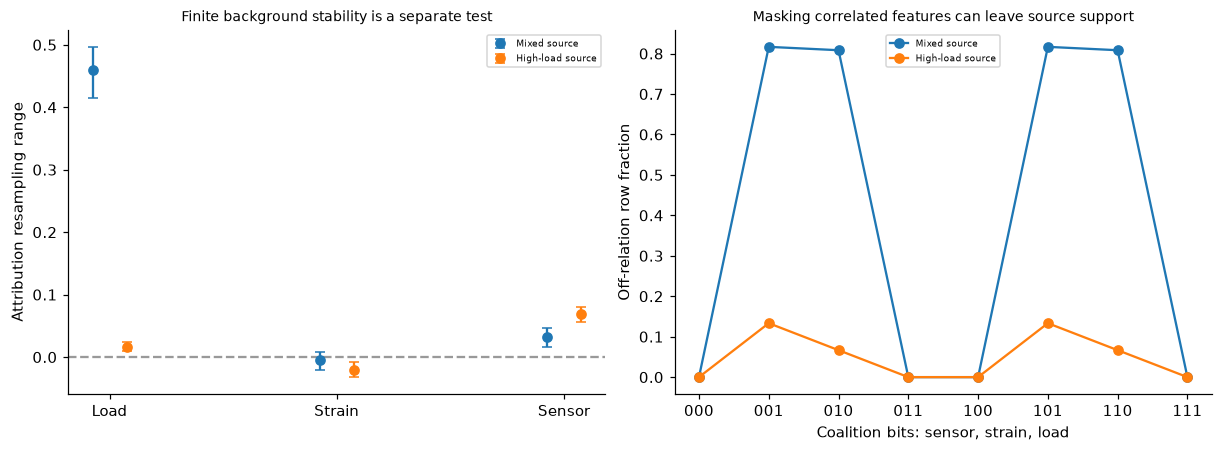

In [3]:
bootstrap={};off={};scale=float(np.std(xs[:,0]-xs[:,1],ddof=1))
for name,b in backgrounds.items():
    vals=np.array([shapley(b[rng.integers(0,120,120)])[0] for _ in range(40)]);bootstrap[name]={'median':np.median(vals,axis=0).tolist(),'central95_range':np.quantile(vals,[.025,.975],axis=0).T.tolist()};fractions=[]
    for mask in range(8):
        z=b.copy()
        for j in range(3):
            if mask&(1<<j):z[:,j]=query[j]
        fractions.append(float(np.mean(abs(z[:,0]-z[:,1])>3*scale)))
    off[name]=fractions;assert vals.shape==(40,3)
assert all(0<=v<=1 for fractions in off.values() for v in fractions);assert all(np.isclose(shapley(b)[0].sum()+shapley(b)[1][0],prediction) for b in backgrounds.values());RESULTS.update(background_bootstrap=bootstrap,off_relation_fraction_by_coalition=off,background_resamples=40,resampling_range_is_not_model_or_causal_uncertainty=True);fig,axes=plt.subplots(1,2,figsize=(11,4))
for j,(name,row) in enumerate(bootstrap.items()):
    mid=np.array(row['median']);bounds=np.array(row['central95_range']);axes[0].errorbar(np.arange(3)+(j-.5)*.15,mid,yerr=np.array([mid-bounds[:,0],bounds[:,1]-mid]),fmt='o',capsize=3,label=name)
axes[0].axhline(0,color='.6',linestyle='--');axes[0].set(xticks=range(3),xticklabels=['Load','Strain','Sensor'],ylabel='Attribution resampling range',title='Finite background stability is a separate test');axes[0].legend(fontsize=6)
for j,(name,frac) in enumerate(off.items()):axes[1].plot(range(8),frac,'o-',label=name)
axes[1].set(xticks=range(8),xticklabels=[f'{k:03b}' for k in range(8)],xlabel='Coalition bits: sensor, strain, load',ylabel='Off-relation row fraction',title='Masking correlated features can leave source support');axes[1].legend(fontsize=6);plt.show()


In [4]:
summary={'example_id':'code_203','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual exact three-feature Shapley coalition enumeration for a fitted classifier', 'two valid empirical background populations with different baselines', 'conditional background-resample variability separated from model uncertainty', 'correlated-feature masking support diagnostic and exact efficiency checks'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual exact three-feature Shapley coalition enumeration for a fitted classifier", "two valid empirical background populations with different baselines", "conditional background-resample variability separated from model uncertainty", "correlated-feature masking support diagnostic and exact efficiency checks"], "elapsed_seconds": 0.614, "example_id": "code_203", "hardware": "Darwin arm64 CPU", "results": {"attribution_output_scale": "probability", "background_bootstrap": {"High-load source": {"central95_range": [[0.010170883174433801, 0.023371912497416065], [-0.032087901919839595, -0.00711331896111388], [0.05606331058739719, 0.07966156865174026]], "median": [0.015677630092657414, -0.02007410864771661, 0.0686360374804948]}, "Mixed source": {"central95_range": [[0.4147095605745652, 0.4967108490130996], [-0.020636012506005344, 0.008129012116247275], [0.01621218108470142, 0.046729281433429894]], "median": [0.46004839825329336, -0.0046358300